# Guided Exercise

In this guided exercise, we learn how to implement a Conditional Random Field (CRF) for typical image processing tasks. We will first model a problem using a CRF and then apply inference algorithms on PGMs to evaluate their performance.

Uncomment the lines in the following cell to install the required libraries and packages.

In [1]:
# !apt update
# !apt install imagemagick
# !apt install pdf2svg
# !apt install texlive texlive-latex-extra
# !apt-get install libboost-dev libboost-graph-dev libboost-program-options-dev libboost-test-dev libgmp-dev cimg-dev

# !pip install Pillow networkx
# !pip install git+https://github.com/mkrphys/ipython-tikzmagic.git
# !pip install git+https://github.com/Oriolrt/pylibdai.git

In [2]:
   !sudo apt-get update -qq
   !sudo apt-get install -y -qq imagemagick pdf2svg texlive texlive-latex-extra cimg-dev libboost-dev libboost-graph-dev libboost-program-options-dev libboost-test-dev libgmp-dev
   !pip install -q numpy cython Pillow networkx
   !pip install -q git+https://github.com/mkrphys/ipython-tikzmagic.git
   !pip install -q --no-build-isolation git+https://github.com/Oriolrt/pylibdai.git

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 257.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-droid-fallback.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../000-fonts-droid-fallback_1%3a6.0.1r16-1.1build1_all.deb ...
Unpacking fonts-droid-fallback (1:6.0.1r16-1.1build1) ...
Selecting previously unselected package fonts-lato.
Preparing to unpack .../00

In [3]:
from dai import dai
import numpy as np
from sklearn import mixture
from PIL import Image
from time import time
import matplotlib.pyplot as plt

In [4]:
%matplotlib inline

Select an image from the data folder, then open it using the Image module. The code below loads the image into memory and displays it.

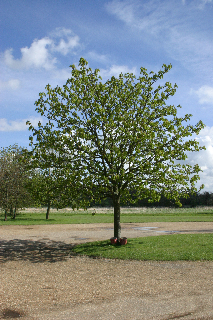

In [5]:
image = Image.open("1.bmp")
image

In [6]:
# from google.colab import drive
# drive.mount('/content/drive')

To assign a unary potential to each pixel we will cluster image pixels according to their colors using a Gaussian Mixture Model.

#### Exercise 1:

Fit a Gaussian Mixture Model and assign a cluster label to each pixel based on the GMM prediction. Try different values for $k$, the number of clusters of the model.

In [7]:
potential = np.asarray(image)
print(f"Size of the original image: {potential.shape}")

original_shape = potential.shape

potential = potential.reshape(
    (original_shape[0] * original_shape[1], original_shape[2])
)
print(f"Size of the unary potentials: {potential.shape}")

k = 10

# TODO:
# Train a GMM model and assign clusters based on the predictions of the GMM
clf = mixture.GaussianMixture(n_components=k, random_state=42)
clf.fit(potential)

clusters = clf.predict(potential)
clusters = clusters.reshape(original_shape[:2])

mean_color = clf.means_.astype(int)

segmented_image = mean_color[clusters].reshape(original_shape)
print(f"Size of the segmented image: {segmented_image.shape}")

Size of the original image: (320, 213, 3)
Size of the unary potentials: (68160, 3)
Size of the segmented image: (320, 213, 3)


In [8]:
def plot_segmentation(original_image, segmented_image, title):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(original_image)

    axes[1].set_title(title)
    axes[1].imshow(segmented_image)

    for ax in axes.ravel():
        ax.set_xticks(())
        ax.set_yticks(())

    fig.tight_layout()
    plt.show()

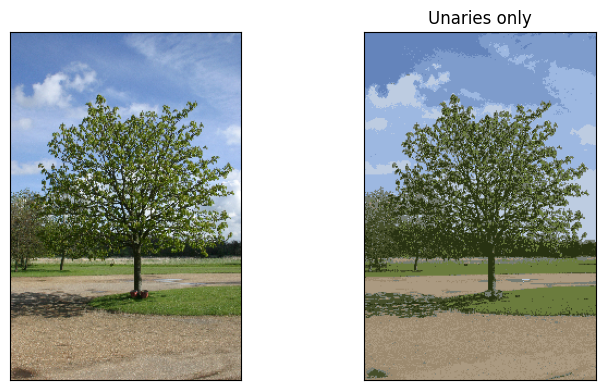

In [9]:
plot_segmentation(image, segmented_image, "Unaries only")

## Inference functions

The following cell defines a function to perform inference on a more complex model based on some parameters.

In [10]:
def inference(factor_list, method, variant):
    props = {
        "inference": variant,
        "updates": "SEQRND",
        "tol": "1e-6",
        "maxiter": "10",
        "logdomain": "0",
        "damping": 0.1,
    }

    start = time()
    inference_result = dai(factor_list, method=method, props=props)[0]
    elapsed_time = time() - start

    segmented_image = mean_color[inference_result.astype(int)]
    segmented_image = segmented_image.reshape(original_shape)

    return segmented_image, elapsed_time

## Building the model
A key step is the construction of the factor graph representation that will represent the dependencies between random variables (represented as nodes in the graph).

We want to represent each pixel as a random variable connected to some of the adjacent pixels. Depending on the connections we want to model, we have to define a different set of factors.

### Pairwise model

The most simple connection topology is a pairwise model, in which each pixel is connected to the pixels adjacent in the vertical and horizontal directions.

We define the function **BuildPairwiseFactorGraph** that, given an image, will return a list of **factors**. Each factor is defined by a tuple of the form:  *( m , f )* , where *m* is a list of variable indices and *f* corresponds to a n-dimensional array with the factor values.

In [11]:
def BuildPairwiseFactorGraph(
    image: Image,
    num_states: int = 1,
    theta: float = 0.2,
    obs_probs: np.array = None,
):
    potential = np.asarray(image)
    original_shape = potential.shape
    n_rows = original_shape[0]
    n_cols = original_shape[1]
    n_nodes = n_rows * n_cols

    indices = np.arange(n_nodes).astype(np.int64)

    down_edges = [(i, i + 1) for i in range(n_nodes) if (i + 1) % n_cols != 0]
    right_edges = [(i, i + n_cols) for i in range(n_nodes - n_cols)]

    adj = down_edges + right_edges

    if obs_probs is not None:
        obs_probs = obs_probs.reshape(n_nodes, num_states)
        unary_factors = [([m], p) for m, p in zip(indices, obs_probs)]

    energy = theta * (np.ones(num_states) - np.eye(num_states))

    pairwise_exp = np.exp(-energy)

    pairwise_factors = [(m, pairwise_exp) for m in adj]

    factor_list = unary_factors + pairwise_factors

    return factor_list

In [12]:
# Compute the probability of each pixel belonging to each Gaussian component
probs = clf.predict_proba(potential)

# Reshape to the original image dimensions + number of states
probs = probs.reshape(original_shape[0], original_shape[1], k)

factor_list = BuildPairwiseFactorGraph(image, num_states=k, obs_probs=probs, theta=4.0)

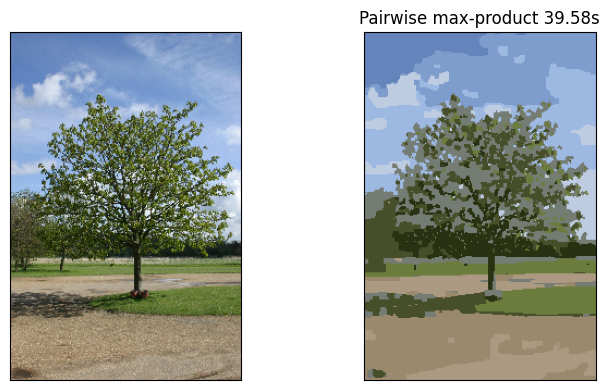

In [13]:
maxprod_image, maxprod_time = inference(factor_list, "BP", "MAXPROD")
plot_segmentation(image, maxprod_image, f"Pairwise max-product {maxprod_time:.2f}s")

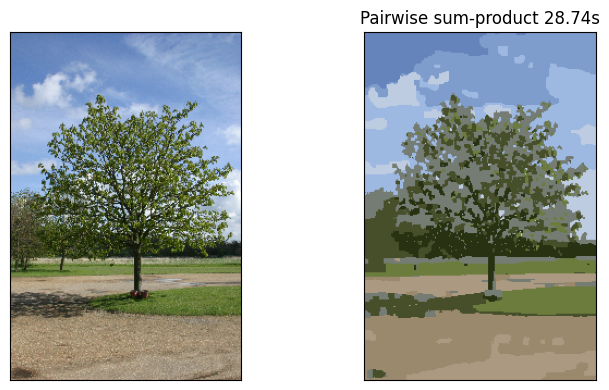

In [14]:
sumprod_image, sumprod_time = inference(factor_list, "BP", "SUMPROD")
plot_segmentation(image, sumprod_image, f"Pairwise sum-product {sumprod_time:.2f}s")

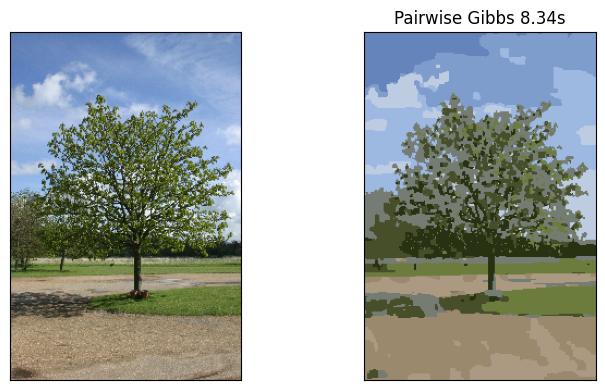

In [15]:
gibbs_image, gibbs_time = inference(factor_list, "GIBBS", None)
plot_segmentation(image, gibbs_image, f"Pairwise Gibbs {gibbs_time:.2f}s")

#### Exercise 2:

Test different values of $k$ and $\theta$ and compare the results of the segmentation.

In [16]:
k_values = [3, 6, 9]
theta_values = [0.5, 2.0, 4.0, 8.0]
results = {}

#chosen the MAXPROD method because we want the most prob label assignation

for k in k_values:
    clf = mixture.GaussianMixture(n_components=k, random_state=42)
    clf.fit(potential)

    probs = clf.predict_proba(potential)
    probs = probs.reshape(original_shape[0], original_shape[1], k)
    mean_color = clf.means_.astype(int)

    for theta in theta_values:
        factor_list = BuildPairwiseFactorGraph(image,
                                              num_states=k,
                                              obs_probs=probs,
                                              theta=theta )

        # Perform Max-Product inference
        segmented_image, elapsed_time = inference(factor_list, "BP", "MAXPROD")
        results[(k, theta)] = {"image": segmented_image, "time": elapsed_time}

        print(f"k={k}, theta={theta}: ", f"{elapsed_time:.2f}s")

k=3, theta=0.5:  14.29s
k=3, theta=2.0:  14.30s
k=3, theta=4.0:  13.84s
k=3, theta=8.0:  13.83s
k=6, theta=0.5:  19.52s
k=6, theta=2.0:  18.18s
k=6, theta=4.0:  19.03s
k=6, theta=8.0:  18.02s
k=9, theta=0.5:  24.78s
k=9, theta=2.0:  24.45s
k=9, theta=4.0:  24.53s
k=9, theta=8.0:  24.16s


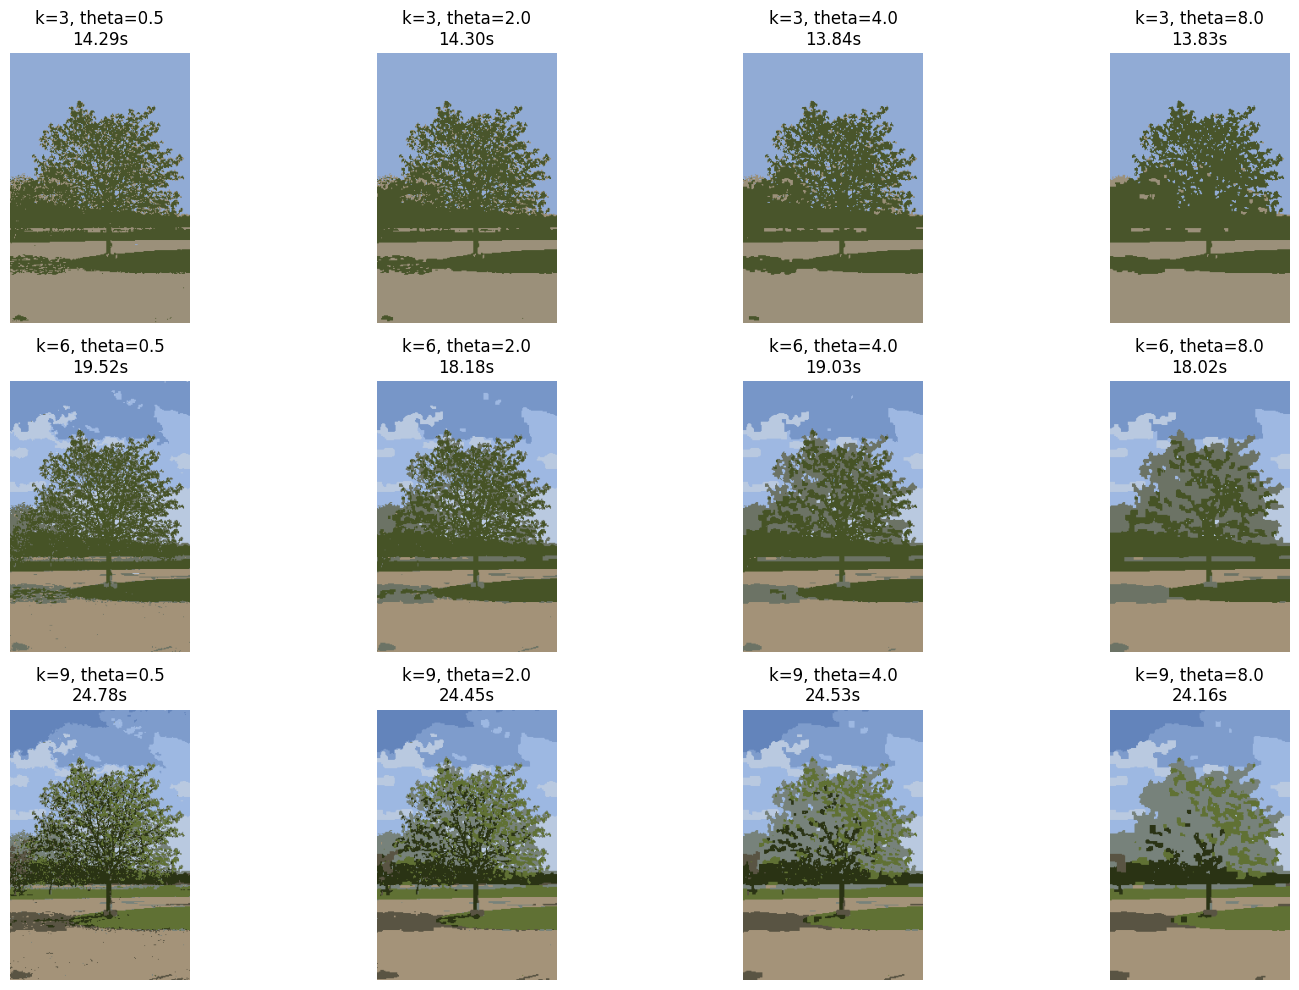

In [18]:
fig, axes = plt.subplots(len(k_values), len(theta_values), figsize=(16, 10))

for i, k in enumerate(k_values):
    for j, theta in enumerate(theta_values):
        result = results[(k, theta)]
        axes[i, j].imshow(result["image"])
        axes[i, j].set_title(f'k={k}, theta={theta}\n{result["time"]:.2f}s')
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

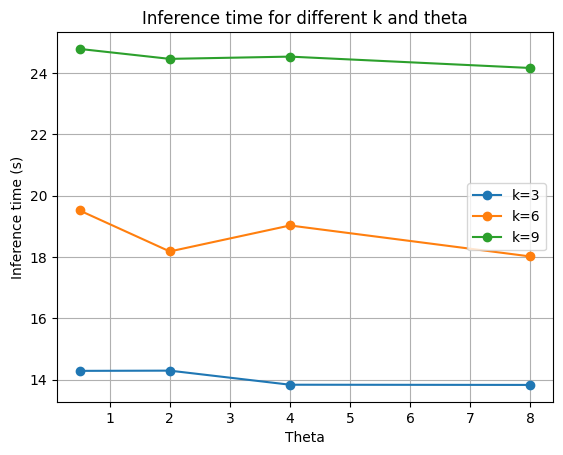

In [19]:
for k in k_values:
    times = [results[(k, theta)]["time"] for theta in theta_values]
    plt.plot( theta_values, times, marker="o", label=f"k={k}")

plt.xlabel("Theta")
plt.ylabel("Inference time (s)")
plt.title("Inference time for different k and theta")
plt.legend()
plt.grid()
plt.show()

### Three order factor model

We can consider a stronger connection between pixels by considering factors that depend on three pixels. Note that in each set of 2 by 2 pixels we consider two different factors.

#### Exercise 3:

Define the three order factors with the corresponding energy function.

In [20]:
def BuildThreeOrderFactorGraph(image: Image,
                              num_states: int = 1,
                              theta_c: float = 0.2,
                              theta_d: float = 0.2,
                              obs_probs: np.array = None,):

    potential = np.asarray(image)
    original_shape = potential.shape
    n_rows = original_shape[0]
    n_cols = original_shape[1]
    n_nodes = n_rows * n_cols

    indices = np.arange(n_nodes).astype(np.int64)

    # Unary factors: probabilities obtained from the GMM
    if obs_probs is not None:
        obs_probs = obs_probs.reshape(n_nodes, num_states)
        unary_factors = [([m], p) for m, p in zip(indices, obs_probs)]
    else:
        unary_factors = []

    # Three-order energy matrices
    x, y, z = np.indices((num_states, num_states, num_states))

    energy_c = theta_c * (~((x == y) & (y == z))) # 0 if the 3 are the same
    energy_d = theta_d * (~((x == y) & (y == z)))

    three_order_exp_c = np.exp(-energy_c)
    three_order_exp_d = np.exp(-energy_d)

    # Generate two three-order factors for each 2x2 block
    three_order_factors = []

    for i in range(n_rows - 1):
        for j in range(n_cols - 1):

            # Flattened indices of the 2x2 block
            A = i * n_cols + j
            B = i * n_cols + (j + 1)
            C = (i + 1) * n_cols + j
            D = (i + 1) * n_cols + (j + 1)

            # First factor: A, B, C
            three_order_factors.append(([A, B, C], three_order_exp_c))

            # Second factor: B, C, D
            three_order_factors.append(([B, C, D], three_order_exp_d))

    factor_list = unary_factors + three_order_factors

    return factor_list


In [21]:
factor_list = BuildThreeOrderFactorGraph(
    image, num_states=k, obs_probs=probs, theta_c=4.0, theta_d=4.0)

In [22]:
print("Number of factors:", len(factor_list))

print("Unary factor shape:", factor_list[0][1].shape)

print("Three-order factor shape:", factor_list[-1][1].shape)

Number of factors: 203416
Unary factor shape: (9,)
Three-order factor shape: (9, 9, 9)


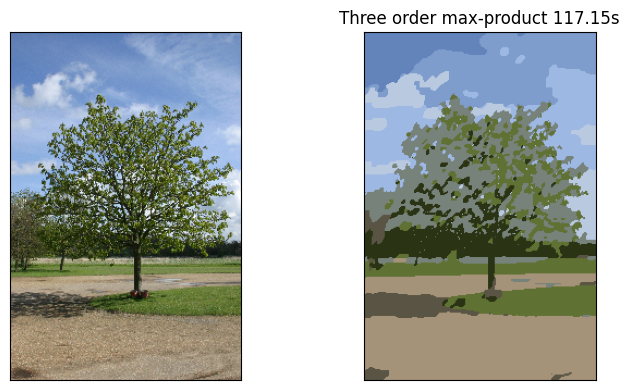

In [23]:
maxprod_image, maxprod_time = inference(factor_list, "BP", "MAXPROD")
plot_segmentation(image, maxprod_image, f"Three order max-product {maxprod_time:.2f}s")

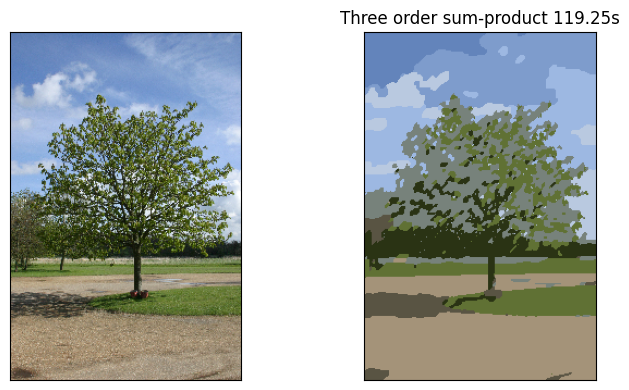

In [24]:
sumprod_image, sumprod_time = inference(factor_list, "BP", "SUMPROD")
plot_segmentation(image, sumprod_image, f"Three order sum-product {sumprod_time:.2f}s")

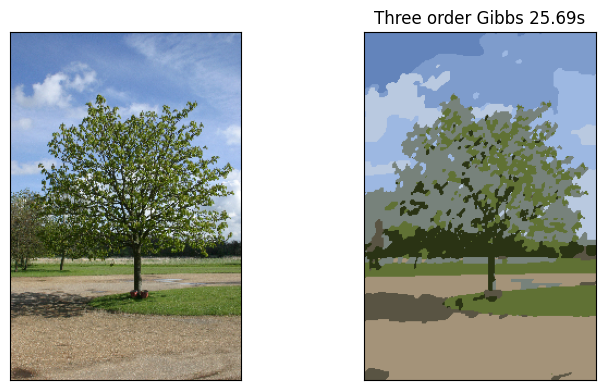

In [25]:
gibbs_image, gibbs_time = inference(factor_list, "GIBBS", None)
plot_segmentation(image, gibbs_image, f"Three order Gibbs {gibbs_time:.2f}s")

#### Exercise 4:

Test different values of $k$, $\theta_c$ and $\theta_d$, and compare the results of the segmentation.

In [26]:
k_values = [3, 6, 9]

theta_c_values = [0.5, 2.0, 4.0]
theta_d_values = [0.5, 2.0, 4.0]

results_3order = {}

In [27]:
for k in k_values:

    # Train GMM
    clf = mixture.GaussianMixture(n_components=k,random_state=42)
    clf.fit(potential)

    # Obtain unary probabilities
    probs = clf.predict_proba(potential)

    probs = probs.reshape(original_shape[0], original_shape[1], k)
    mean_color = clf.means_.astype(int)

    for theta_c in theta_c_values:
        for theta_d in theta_d_values:

            factor_list = BuildThreeOrderFactorGraph(
                image,
                num_states=k,
                obs_probs=probs,
                theta_c=theta_c,
                theta_d=theta_d)

            # MAX-PRODUCT inference
            segmented_image, elapsed_time = inference( factor_list, "BP", "MAXPROD")
            results_3order[(k, theta_c, theta_d)] = { "image": segmented_image, "time": elapsed_time }
            print( f"k={k}, theta_c={theta_c}, " f"theta_d={theta_d}: {elapsed_time:.2f}s" )

k=3, theta_c=0.5, theta_d=0.5: 24.66s
k=3, theta_c=0.5, theta_d=2.0: 24.85s
k=3, theta_c=0.5, theta_d=4.0: 24.90s
k=3, theta_c=2.0, theta_d=0.5: 24.87s
k=3, theta_c=2.0, theta_d=2.0: 24.90s
k=3, theta_c=2.0, theta_d=4.0: 24.95s
k=3, theta_c=4.0, theta_d=0.5: 26.23s
k=3, theta_c=4.0, theta_d=2.0: 25.62s
k=3, theta_c=4.0, theta_d=4.0: 25.00s
k=6, theta_c=0.5, theta_d=0.5: 58.46s
k=6, theta_c=0.5, theta_d=2.0: 56.52s
k=6, theta_c=0.5, theta_d=4.0: 58.50s
k=6, theta_c=2.0, theta_d=0.5: 56.74s
k=6, theta_c=2.0, theta_d=2.0: 58.98s
k=6, theta_c=2.0, theta_d=4.0: 56.76s
k=6, theta_c=4.0, theta_d=0.5: 60.32s
k=6, theta_c=4.0, theta_d=2.0: 60.84s
k=6, theta_c=4.0, theta_d=4.0: 57.02s
k=9, theta_c=0.5, theta_d=0.5: 108.31s
k=9, theta_c=0.5, theta_d=2.0: 110.91s
k=9, theta_c=0.5, theta_d=4.0: 110.44s
k=9, theta_c=2.0, theta_d=0.5: 107.77s
k=9, theta_c=2.0, theta_d=2.0: 108.85s
k=9, theta_c=2.0, theta_d=4.0: 108.82s
k=9, theta_c=4.0, theta_d=0.5: 110.75s
k=9, theta_c=4.0, theta_d=2.0: 109.24s
k=9,

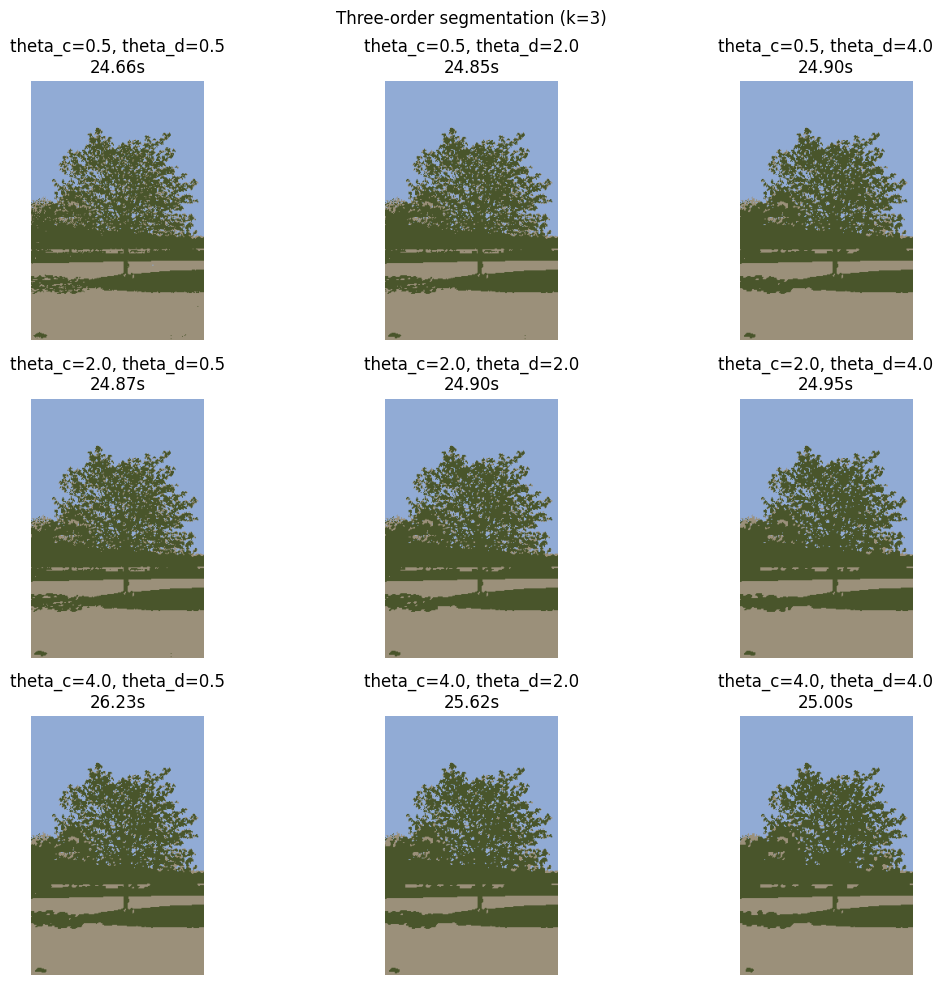

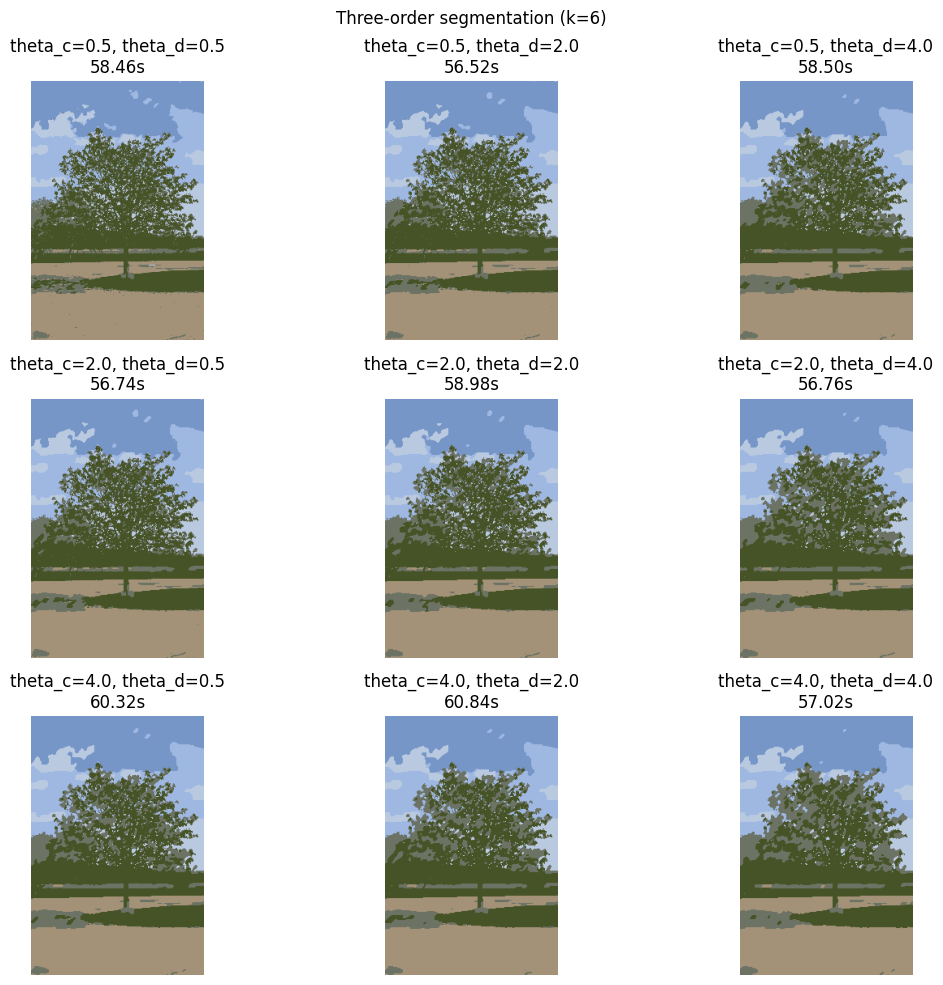

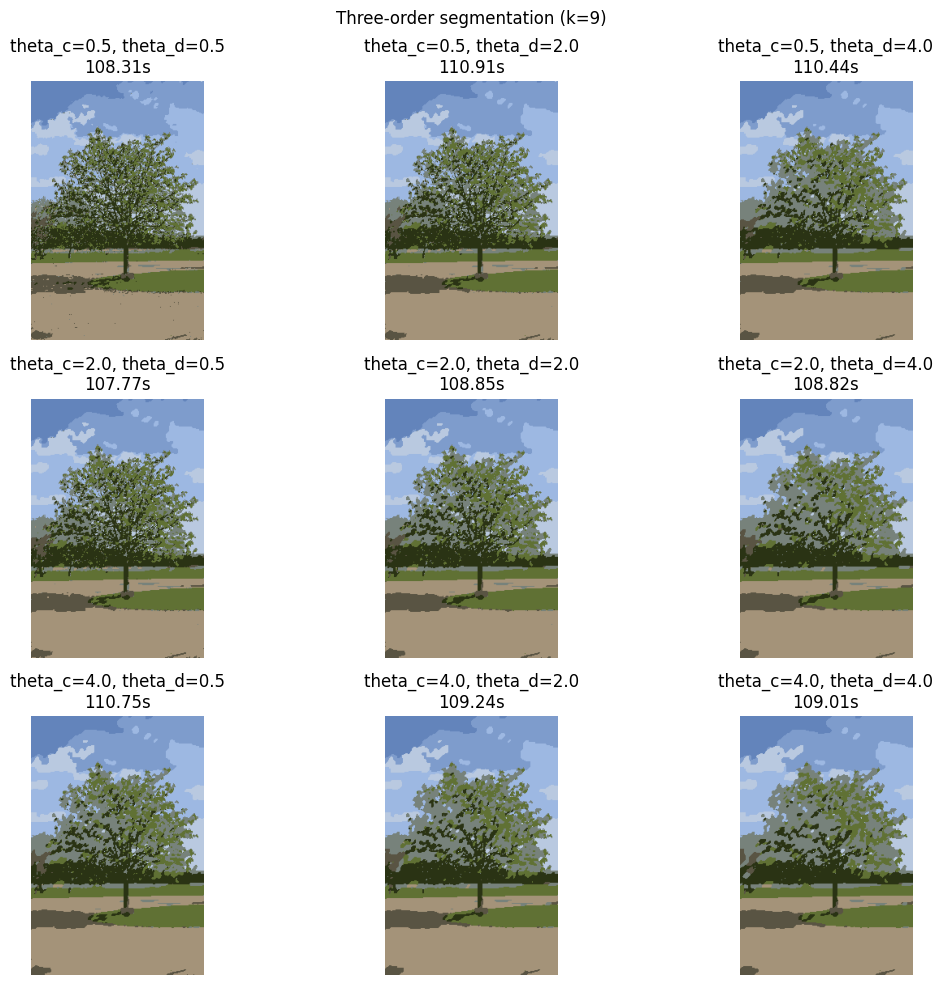

In [32]:
for k in k_values:

    fig, axes = plt.subplots(
        len(theta_c_values),
        len(theta_d_values),
        figsize=(12, 10),
        squeeze=False
    )

    for i, theta_c in enumerate(theta_c_values):
        for j, theta_d in enumerate(theta_d_values):

            result = results_3order[(k, theta_c, theta_d)]

            axes[i, j].imshow(result["image"])

            axes[i, j].set_title(
                f"theta_c={theta_c}, theta_d={theta_d}\n"
                f'{result["time"]:.2f}s'
            )

            axes[i, j].axis("off")

    fig.suptitle(f"Three-order segmentation (k={k})")
    plt.tight_layout()
    plt.show()

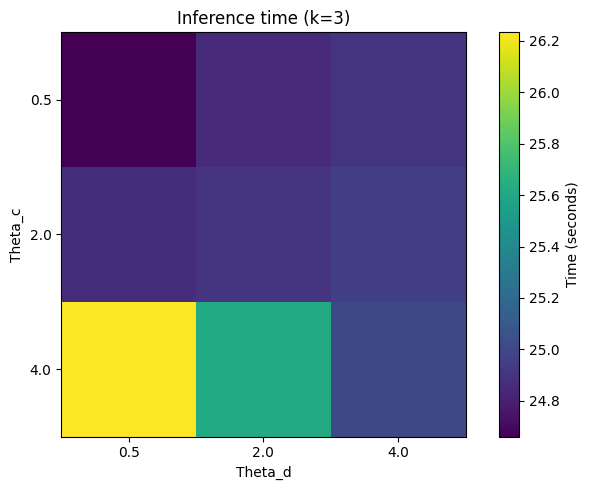

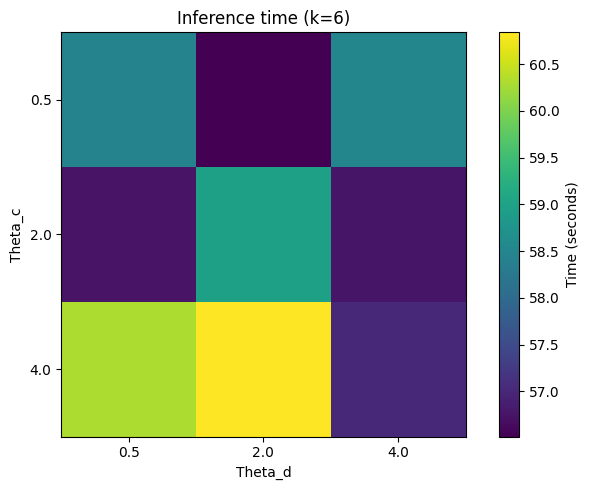

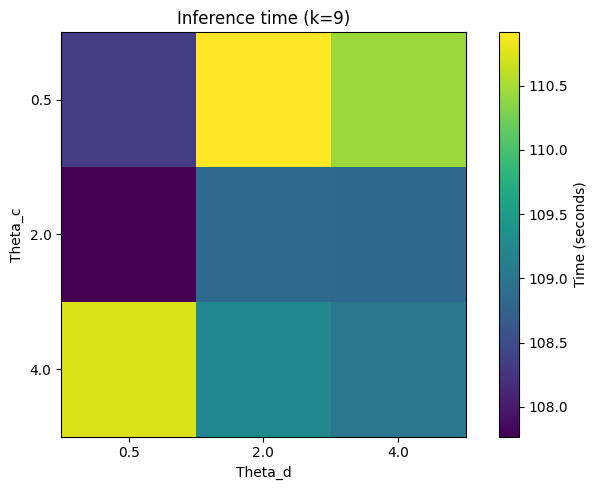

In [34]:
for k in k_values:

    times = np.array([
        [
            results_3order[(k, theta_c, theta_d)]["time"]
            for theta_d in theta_d_values
        ]
        for theta_c in theta_c_values
    ])

    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(times, cmap="viridis")

    ax.set_xticks(range(len(theta_d_values)))
    ax.set_xticklabels(theta_d_values)

    ax.set_yticks(range(len(theta_c_values)))
    ax.set_yticklabels(theta_c_values)

    ax.set_xlabel("Theta_d")
    ax.set_ylabel("Theta_c")
    ax.set_title(f"Inference time (k={k})")

    fig.colorbar(im, ax=ax, label="Time (seconds)")

    plt.tight_layout()
    plt.show()